# PDZ Trans-1 and Trans-2 EDA

## SciStanPy alignment and FLIP reconciliation

This notebook profiles both PDZ trans count libraries, inspects their diagnosed HMC artifacts, and reconstructs the public FLIP `PDZ:CRIPT` sequence keys.

The primary count-loading path is `flipv3.flip_dsets.load_pdz_dataset`, which performs the sequence grouping and establishes the variant order used by the SciStanPy fits. A direct pandas implementation is retained only as a parity check.

The diagnosed files are about 126 GB each. All result-file access is lazy, and posterior EDA is restricted to sampled draws and variants.

## 1. Configure Paths and Import Dependencies

Resolve the repository independently of the notebook launch directory, import the local SciStanPy snapshot, and define the raw, HMC, FLIP, and output paths. Shared PDZ constants are local because `flip_dsets.py` does not expose them.

In [3]:
from pathlib import Path
import inspect
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr
from IPython.display import display


def find_repo_root() -> Path:
    workspace_hint = Path(
        r"C:\Users\t-renatob\OneDrive - Microsoft\Desktop\RenatoBerlinghieri\prob-protein-fitness"
    )
    starts = [Path.cwd(), workspace_hint]
    for start in starts:
        for candidate in [start, *start.parents]:
            if (candidate / "data").is_dir() and (candidate / "SciStanPy" / "flipv3").is_dir():
                return candidate
    raise FileNotFoundError("Could not locate a repository containing data/ and SciStanPy/flipv3/.")


repo_root = find_repo_root()
data_dir = repo_root / "data"
scistanpy_root = repo_root / "SciStanPy"
amlt_dir = repo_root / "amlt" / "large-clean"
output_dir = repo_root / "results" / "pdz_trans_eda"

if str(scistanpy_root) not in sys.path:
    sys.path.insert(0, str(scistanpy_root))

from flipv3 import flip_dsets

RAW_PATHS = {
    "trans-1": data_dir / "trans-1.tsv",
    "trans-2": data_dir / "trans-2.tsv",
}
RESULT_PATHS = {
    "trans-1": amlt_dir / "large-clean_82" / "pdz" / "trans-1" / "pdz_trans-1_exponential_exponential_diagnosed.nc",
    "trans-2": amlt_dir / "large-clean_88" / "pdz" / "trans-2" / "pdz_trans-2_exponential_exponential_diagnosed.nc",
}
FLIP_PATH = data_dir / "single_to_double_from_flip_repo.csv"

WT_PDZ = "GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA"
PDZ_HALF_LENGTH = 50
CRIPT_LENGTH = 8
INPUT_COLUMNS = [
    "input1_e1_s0_bNA_count",
    "input2_e2_s0_bNA_count",
    "input3_e3_s0_bNA_count",
]
OUTPUT_COLUMNS = [
    "output1A_e1_s1_b1_count",
    "output2A_e2_s1_b1_count",
    "output3A_e3_s1_b1_count",
]
COUNT_COLUMNS = [*INPUT_COLUMNS, *OUTPUT_COLUMNS]
SOURCE_COLORS = {"trans-1": "#247BA0", "trans-2": "#F28E2B"}

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)

file_inventory = pd.DataFrame(
    [
        {
            "kind": kind,
            "source": source,
            "path": str(path.relative_to(repo_root)),
            "exists": path.exists(),
            "size_gb": path.stat().st_size / 1e9 if path.exists() else np.nan,
        }
        for kind, paths in [("raw counts", RAW_PATHS), ("diagnosed HMC", RESULT_PATHS)]
        for source, path in paths.items()
    ]
    + [
        {
            "kind": "FLIP split",
            "source": "PDZ",
            "path": str(FLIP_PATH.relative_to(repo_root)),
            "exists": FLIP_PATH.exists(),
            "size_gb": FLIP_PATH.stat().st_size / 1e9 if FLIP_PATH.exists() else np.nan,
        }
    ]
)

assert all(path.exists() for path in RAW_PATHS.values()), "One or more raw trans files are missing."
assert FLIP_PATH.exists(), f"FLIP split file not found: {FLIP_PATH}"

print(f"Repository root: {repo_root}")
print(f"SciStanPy source: {scistanpy_root}")
display(file_inventory)

Repository root: c:\Users\t-renatob\OneDrive - Microsoft\Desktop\RenatoBerlinghieri\prob-protein-fitness
SciStanPy source: c:\Users\t-renatob\OneDrive - Microsoft\Desktop\RenatoBerlinghieri\prob-protein-fitness\SciStanPy


,kind,source,path,exists,size_gb
0,raw counts,trans-1,data\trans-1.tsv,True,0.039649
1,raw counts,trans-2,data\trans-2.tsv,True,0.039998
2,diagnosed HMC,trans-1,amlt\large-clean\large-clean_82\pdz\trans-1\pdz_trans-1_exponential_exponential_diagnosed.nc,True,126.234420
3,diagnosed HMC,trans-2,amlt\large-clean\large-clean_88\pdz\trans-2\pdz_trans-2_exponential_exponential_diagnosed.nc,True,126.600320
4,FLIP split,PDZ,data\single_to_double_from_flip_repo.csv,True,0.000098


## 2. Inspect SciStanPy FLIP Dataset Utilities

Inspect the local module rather than assuming an API. In this snapshot, `load_pdz_dataset()` is the reusable PDZ loader: it groups duplicate `aa_seq` rows, sums counts, and returns the exact variant order used by the fits. `reformat_pdz_zenodo_dset()` handles Zenodo nucleotide files. There is currently no exported helper that performs the trans-specific WT completion and `PDZ:CRIPT` reconstruction, so that small source-specific transformation remains in this notebook.

In [4]:
public_functions = [
    (name, function)
    for name, function in inspect.getmembers(flip_dsets, inspect.isfunction)
    if function.__module__ == flip_dsets.__name__ and not name.startswith("_")
]

api_inventory = pd.DataFrame(
    [
        {
            "function": name,
            "signature": str(inspect.signature(function)),
            "category": (
                "PDZ loader/reformatter"
                if "pdz" in name
                else "dataset loader"
                if name.startswith("load_")
                else "other"
            ),
            "summary": (inspect.getdoc(function) or "").splitlines()[0],
        }
        for name, function in public_functions
    ]
)

pdz_reconstruction_apis = [
    name
    for name, _ in public_functions
    if "pdz" in name and any(token in name for token in ("reconstruct", "sequence", "combine", "truncate"))
]

assert "load_pdz_dataset" in api_inventory["function"].tolist()
print("Exported PDZ reconstruction helpers:", pdz_reconstruction_apis or "none")
display(api_inventory)

print("\nSource for the primary loader:\n")
print(inspect.getsource(flip_dsets.load_pdz_dataset))

Exported PDZ reconstruction helpers: none


,function,signature,category,summary
0,load_k50_data,(data_dir: str) -> dict,dataset loader,Loads the data from Tsuboyama et al.
1,load_nuclease_data,"(data_dir: str, gen: Literal['G1', 'G2', 'G3', 'G4']) -> dict",dataset loader,Loads the Nuclease dataset. The data is described in
2,load_pdz_dataset,"(filepath: str) -> dict[str, NDArray[numpy.int64]]",PDZ loader/reformatter,Loads a given PDZ3 dataset file and returns the starting and ending counts.
3,load_trpb_dataset,"(filepath: str, libname: str | None = None) -> dict[str, NDArray | list[str]]",dataset loader,Load a TrpB dataset from Johnston et al.
4,reformat_pdz_zenodo_dset,"(infile: str, outfile: str) -> None",PDZ loader/reformatter,Converts the trans dataset files found on Zenodo into the format sent by Taraneh



Source for the primary loader:

def load_pdz_dataset(filepath: str) -> dict[str, npt.NDArray[np.int64]]:
    """Loads a given PDZ3 dataset file and returns the starting and ending counts.
    This function is appropriate for the files sent by Taraneh Zarin.

    Args:
        filepath (str): Path to the file to load.

    Returns:
        dict[str, npt.NDArray[np.int64]]: A dictionary with two keys:
            'starting_counts' and 'ending_counts', each containing a numpy array of
            the respective counts.
    """
    # Load the data. We are grouping all data belonging to unique amino acid sequences
    # together by summing the counts
    df = (
        pd.read_csv(
            filepath,
            sep="\t",
            usecols=(
                "aa_seq",
                "input1_e1_s0_bNA_count",
                "input2_e2_s0_bNA_count",
                "input3_e3_s0_bNA_count",
                "output1A_e1_s1_b1_count",
                "output2A_e2_s1_b1_count",
         

## 3. Load Trans-1 and Trans-2 with SciStanPy

Use `load_pdz_dataset()` as the primary interface. The compatibility wrapper converts its `variants`, `starting_counts`, and `timepoint_counts` arrays into a tidy table while preserving the loader's variant order as `variant_index`.

For validation only, the raw TSVs are also retained and independently grouped with pandas.

In [5]:
def load_pdz_frame(source: str, path: Path) -> tuple[dict, pd.DataFrame]:
    dataset = flip_dsets.load_pdz_dataset(str(path))
    variants = list(dataset["variants"])
    starting_counts = np.asarray(dataset["starting_counts"])
    timepoint_counts = np.asarray(dataset["timepoint_counts"])

    expected_shape = (3, len(variants))
    if starting_counts.shape != expected_shape or timepoint_counts.shape != expected_shape:
        raise ValueError(
            f"{source}: expected count arrays with shape {expected_shape}; "
            f"found {starting_counts.shape} and {timepoint_counts.shape}."
        )

    frame = pd.DataFrame(
        {
            "source": source,
            "variant_index": np.arange(len(variants), dtype=np.int64),
            "aa_seq": variants,
        }
    )
    frame[INPUT_COLUMNS] = starting_counts.T
    frame[OUTPUT_COLUMNS] = timepoint_counts.T
    return dataset, frame


scistanpy_datasets = {}
source_frames = {}
raw_source_frames = {}
loader_parity_rows = []

for source, path in RAW_PATHS.items():
    dataset, frame = load_pdz_frame(source, path)
    raw = pd.read_csv(path, sep="\t", usecols=["aa_seq", *COUNT_COLUMNS])
    direct_grouped = raw.groupby("aa_seq", as_index=False)[COUNT_COLUMNS].sum()

    variants_equal = frame["aa_seq"].tolist() == direct_grouped["aa_seq"].tolist()
    counts_equal = np.array_equal(
        frame[COUNT_COLUMNS].to_numpy(),
        direct_grouped[COUNT_COLUMNS].to_numpy(),
    )

    loader_parity_rows.append(
        {
            "source": source,
            "raw_rows": len(raw),
            "grouped_variants": len(frame),
            "variant_order_equals_direct_groupby": variants_equal,
            "counts_equal_direct_groupby": counts_equal,
        }
    )
    scistanpy_datasets[source] = dataset
    source_frames[source] = frame
    raw_source_frames[source] = raw.assign(source=source)

loader_parity = pd.DataFrame(loader_parity_rows)
assert loader_parity["variant_order_equals_direct_groupby"].all()
assert loader_parity["counts_equal_direct_groupby"].all()

display(loader_parity)
for source, frame in source_frames.items():
    print(f"\n{source}: {len(frame):,} grouped variants")
    display(frame.head(3))

,source,raw_rows,grouped_variants,variant_order_equals_direct_groupby,counts_equal_direct_groupby
0,trans-1,158655,150769,True,True
1,trans-2,159511,151624,True,True



trans-1: 150,769 grouped variants


,source,variant_index,aa_seq,input1_e1_s0_bNA_count,input2_e2_s0_bNA_count,input3_e3_s0_bNA_count,output1A_e1_s1_b1_count,output2A_e2_s1_b1_count,output3A_e3_s1_b1_count
0,trans-1,0,*EEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGE*NYKQTSV,5,10,7,0,0,0
1,trans-1,1,*EEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGEANYKQTSV,12,22,13,0,0,1
2,trans-1,2,*EEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGECNYKQTSV,4,5,10,0,1,2



trans-2: 151,624 grouped variants


,source,variant_index,aa_seq,input1_e1_s0_bNA_count,input2_e2_s0_bNA_count,input3_e3_s0_bNA_count,output1A_e1_s1_b1_count,output2A_e2_s1_b1_count,output3A_e3_s1_b1_count
0,trans-2,0,*RKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA*NYKQTSV,11,17,23,0,0,0
1,trans-2,1,*RKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEAANYKQTSV,12,22,34,2,1,1
2,trans-2,2,*RKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEACNYKQTSV,6,9,17,0,0,1


## 4. Validate Schemas and Count Columns

Validate the assumptions required by the loader and reconstruction: all six count columns must exist, be numeric and nonnegative; sequences must be non-null and long enough to contain a 50-aa PDZ segment plus an 8-aa CRIPT segment; and grouped SciStanPy variants must be unique.

In [6]:
schema_rows = []

for source in RAW_PATHS:
    raw = raw_source_frames[source]
    grouped = source_frames[source]
    missing_columns = sorted(set(["aa_seq", *COUNT_COLUMNS]) - set(raw.columns))
    null_sequences = int(raw["aa_seq"].isna().sum())
    null_counts = int(raw[COUNT_COLUMNS].isna().sum().sum())
    nonnumeric_counts = [
        column for column in COUNT_COLUMNS if not pd.api.types.is_numeric_dtype(raw[column])
    ]
    negative_counts = int((raw[COUNT_COLUMNS] < 0).sum().sum())
    sequence_lengths = raw["aa_seq"].str.len()
    too_short = int((sequence_lengths < PDZ_HALF_LENGTH + CRIPT_LENGTH).sum())

    schema_rows.append(
        {
            "source": source,
            "missing_required_columns": len(missing_columns),
            "null_sequences": null_sequences,
            "null_count_values": null_counts,
            "nonnumeric_count_columns": len(nonnumeric_counts),
            "negative_count_values": negative_counts,
            "sequences_shorter_than_58": too_short,
            "raw_duplicate_sequence_rows": int(raw["aa_seq"].duplicated(keep=False).sum()),
            "grouped_sequence_keys_unique": bool(grouped["aa_seq"].is_unique),
            "rows_with_stop": int(raw["aa_seq"].str.contains("*", regex=False).sum()),
        }
    )

    assert not missing_columns, f"{source} is missing columns: {missing_columns}"
    assert null_sequences == 0, f"{source} contains null aa_seq values."
    assert null_counts == 0, f"{source} contains null count values."
    assert not nonnumeric_counts, f"{source} has nonnumeric count columns: {nonnumeric_counts}"
    assert negative_counts == 0, f"{source} contains negative counts."
    assert too_short == 0, f"{source} has sequences shorter than 58 amino acids."
    assert grouped["aa_seq"].is_unique, f"{source} SciStanPy variants are not unique."
    assert np.issubdtype(grouped[COUNT_COLUMNS].to_numpy().dtype, np.integer)

schema_validation = pd.DataFrame(schema_rows)
display(schema_validation)

,source,missing_required_columns,null_sequences,null_count_values,nonnumeric_count_columns,negative_count_values,sequences_shorter_than_58,raw_duplicate_sequence_rows,grouped_sequence_keys_unique,rows_with_stop
0,trans-1,0,0,0,0,0,0,9016,True,6709
1,trans-2,0,0,0,0,0,0,9017,True,6756


## 5. Profile Trans-1 and Trans-2

Summarize raw sequencing rows and the grouped variant universe used by SciStanPy. Count totals below use grouped rows, which conserve the raw totals exactly.

In [7]:
profile_rows = []
count_depth_rows = []

for source in RAW_PATHS:
    raw = raw_source_frames[source]
    grouped = source_frames[source].copy()
    grouped["sequence_length"] = grouped["aa_seq"].str.len()
    grouped["total_input"] = grouped[INPUT_COLUMNS].sum(axis=1)
    grouped["total_output"] = grouped[OUTPUT_COLUMNS].sum(axis=1)
    grouped["total_counts"] = grouped["total_input"] + grouped["total_output"]
    source_frames[source] = grouped

    lengths = grouped["sequence_length"]
    profile_rows.append(
        {
            "source": source,
            "raw_rows": len(raw),
            "grouped_unique_sequences": len(grouped),
            "raw_duplicate_sequence_rows": int(raw["aa_seq"].duplicated(keep=False).sum()),
            "min_length": int(lengths.min()),
            "median_length": float(lengths.median()),
            "max_length": int(lengths.max()),
            "sequences_with_stop": int(grouped["aa_seq"].str.contains("*", regex=False).sum()),
            "all_zero_count_rows": int(grouped[COUNT_COLUMNS].eq(0).all(axis=1).sum()),
            "zero_output_rows": int(grouped[OUTPUT_COLUMNS].eq(0).all(axis=1).sum()),
            "total_input_counts": int(grouped["total_input"].sum()),
            "total_output_counts": int(grouped["total_output"].sum()),
        }
    )

    for column in COUNT_COLUMNS:
        count_depth_rows.append(
            {
                "source": source,
                "count_column": column,
                "stage": "input" if column in INPUT_COLUMNS else "output",
                "total_counts": int(grouped[column].sum()),
                "zero_fraction": float(grouped[column].eq(0).mean()),
                "median_nonzero": float(grouped.loc[grouped[column] > 0, column].median()),
            }
        )

profile_summary = pd.DataFrame(profile_rows)
count_depth_summary = pd.DataFrame(count_depth_rows)

display(profile_summary)
display(count_depth_summary)

,source,raw_rows,grouped_unique_sequences,raw_duplicate_sequence_rows,min_length,median_length,max_length,sequences_with_stop,all_zero_count_rows,zero_output_rows,total_input_counts,total_output_counts
0,trans-1,158655,150769,9016,58,58.0,58,6538,32,10823,13646608,30051656
1,trans-2,159511,151624,9017,58,58.0,58,6585,57,5914,16332120,18581494


,source,count_column,stage,total_counts,zero_fraction,median_nonzero
0,trans-1,input1_e1_s0_bNA_count,input,4182411,0.051576,15.0
1,trans-1,input2_e2_s0_bNA_count,input,4510198,0.047636,18.0
2,trans-1,input3_e3_s0_bNA_count,input,4953999,0.044605,19.0
3,trans-1,output1A_e1_s1_b1_count,output,7972905,0.210474,15.0
4,trans-1,output2A_e2_s1_b1_count,output,16297743,0.119342,25.0
5,trans-1,output3A_e3_s1_b1_count,output,5781008,0.201361,13.0
6,trans-2,input1_e1_s0_bNA_count,input,4803106,0.004201,24.0
7,trans-2,input2_e2_s0_bNA_count,input,5051861,0.003825,25.0
8,trans-2,input3_e3_s0_bNA_count,input,6477153,0.003502,33.0
9,trans-2,output1A_e1_s1_b1_count,output,6570997,0.122309,23.0


## 6. Compare Sequence and Count Distributions

All encoded sequences are expected to have length 58, so the length panel acts as a structural check. Count panels use `log1p` to retain zero-count variants while showing the long-tailed depth distributions.

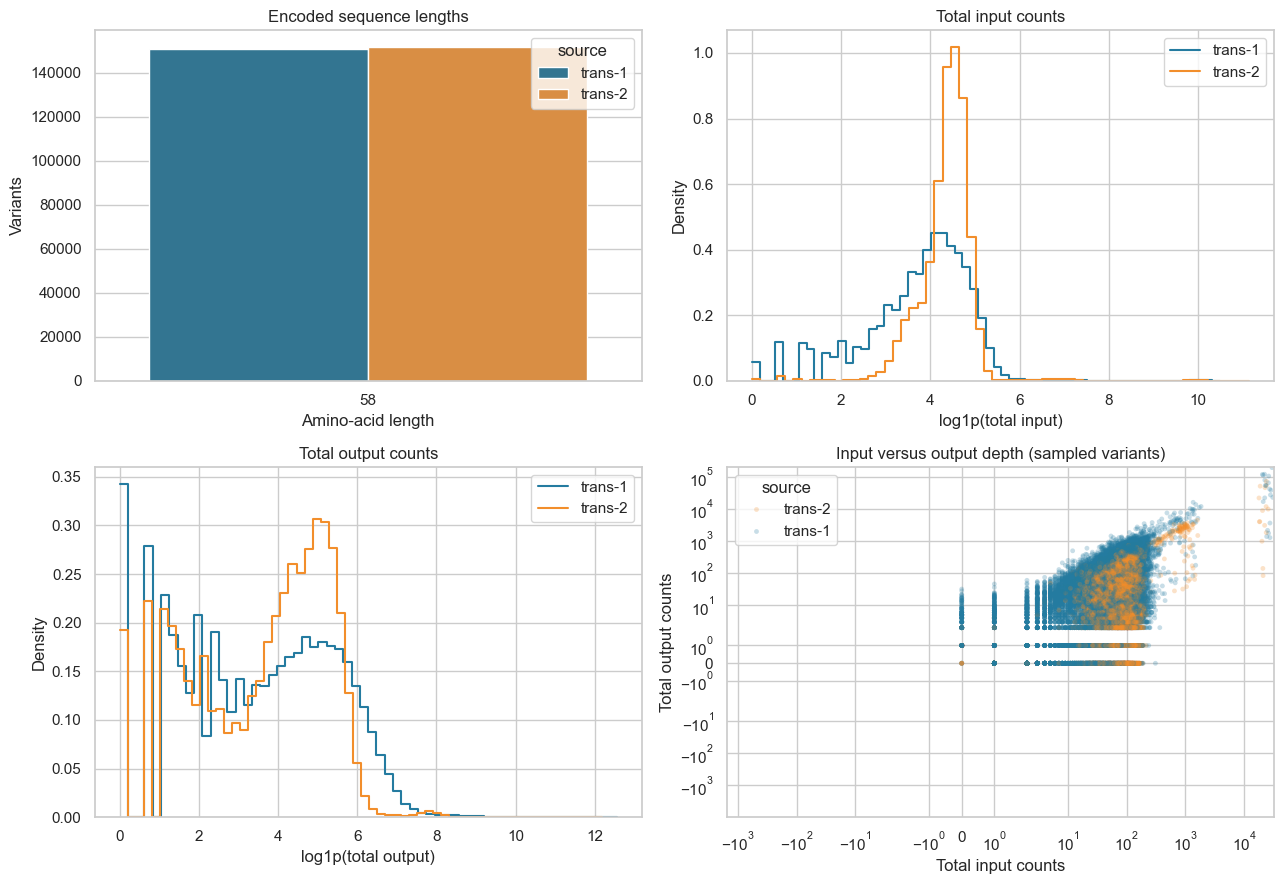

,category,sequences
0,shared encoded aa_seq,0
1,trans-1 only,150769
2,trans-2 only,151624


source,trans-1,trans-2
count_column,,
input1_e1_s0_bNA_count,4182411,4803106
input2_e2_s0_bNA_count,4510198,5051861
input3_e3_s0_bNA_count,4953999,6477153
output1A_e1_s1_b1_count,7972905,6570997
output2A_e2_s1_b1_count,16297743,6801072
output3A_e3_s1_b1_count,5781008,5209425


In [8]:
combined_grouped = pd.concat(source_frames.values(), ignore_index=True)
raw_sequence_sets = {
    source: set(frame["aa_seq"])
    for source, frame in source_frames.items()
}
raw_overlap_summary = pd.DataFrame(
    [
        {"category": "shared encoded aa_seq", "sequences": len(raw_sequence_sets["trans-1"] & raw_sequence_sets["trans-2"])},
        {"category": "trans-1 only", "sequences": len(raw_sequence_sets["trans-1"] - raw_sequence_sets["trans-2"])},
        {"category": "trans-2 only", "sequences": len(raw_sequence_sets["trans-2"] - raw_sequence_sets["trans-1"])},
    ]
)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.countplot(
    data=combined_grouped,
    x="sequence_length",
    hue="source",
    palette=SOURCE_COLORS,
    ax=axes[0, 0],
)
axes[0, 0].set(title="Encoded sequence lengths", xlabel="Amino-acid length", ylabel="Variants")

for source, frame in source_frames.items():
    sns.histplot(
        np.log1p(frame["total_input"]),
        bins=60,
        element="step",
        fill=False,
        stat="density",
        color=SOURCE_COLORS[source],
        label=source,
        ax=axes[0, 1],
    )
axes[0, 1].set(title="Total input counts", xlabel="log1p(total input)")
axes[0, 1].legend()

for source, frame in source_frames.items():
    sns.histplot(
        np.log1p(frame["total_output"]),
        bins=60,
        element="step",
        fill=False,
        stat="density",
        color=SOURCE_COLORS[source],
        label=source,
        ax=axes[1, 0],
    )
axes[1, 0].set(title="Total output counts", xlabel="log1p(total output)")
axes[1, 0].legend()

plot_sample = combined_grouped.sample(min(40_000, len(combined_grouped)), random_state=7)
sns.scatterplot(
    data=plot_sample,
    x="total_input",
    y="total_output",
    hue="source",
    palette=SOURCE_COLORS,
    alpha=0.25,
    s=12,
    linewidth=0,
    ax=axes[1, 1],
)
axes[1, 1].set(
    title="Input versus output depth (sampled variants)",
    xscale="symlog",
    yscale="symlog",
    xlabel="Total input counts",
    ylabel="Total output counts",
)

plt.tight_layout()
plt.show()

depth_pivot = count_depth_summary.pivot(index="count_column", columns="source", values="total_counts")
display(raw_overlap_summary)
display(depth_pivot)

## 7. Analyze Replicate Counts and Enrichment

Compare input and output replicates with Spearman correlations. The exploratory enrichment proxy for replicate $r$ is

$$E_r = \log_2\left(\frac{c_{\mathrm{out},r} + 0.5}{c_{\mathrm{in},r} + 0.5}\right).$$

It is useful for EDA, but it is not a replacement for the probabilistic growth-rate model.

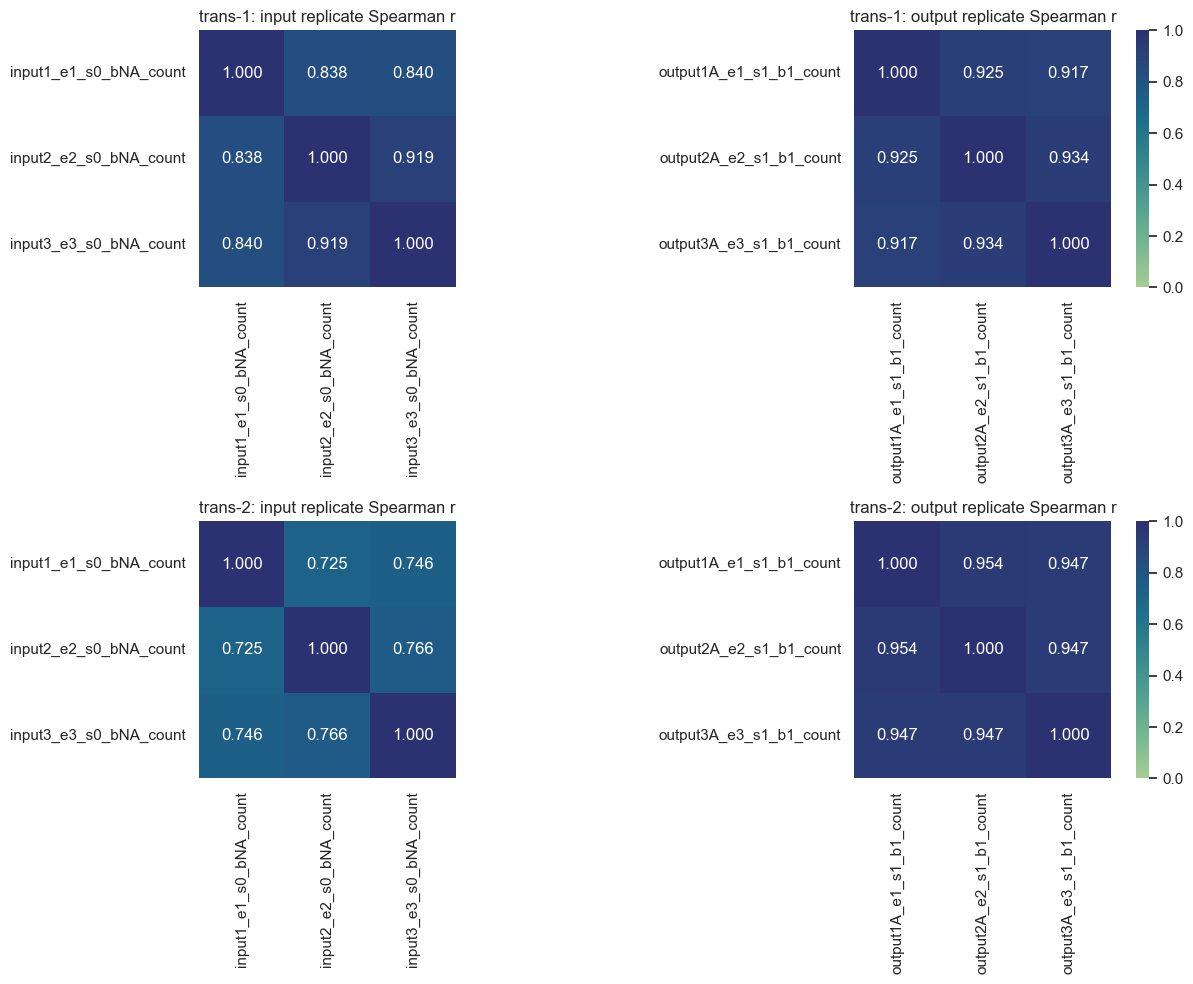

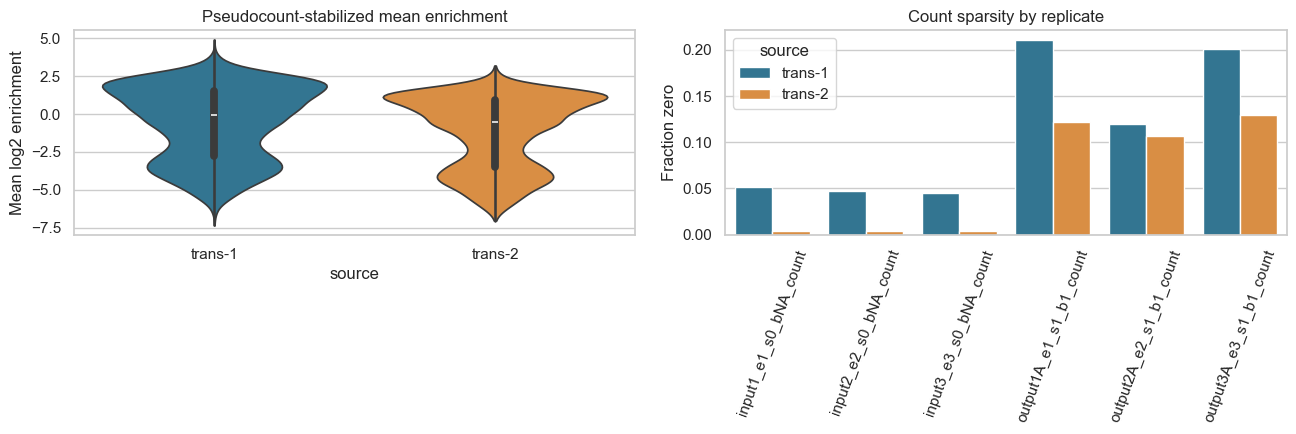

,source,stage,replicate_1,replicate_2,spearman_r
0,trans-1,input,input1_e1_s0_bNA_count,input2_e2_s0_bNA_count,0.838064
1,trans-1,input,input1_e1_s0_bNA_count,input3_e3_s0_bNA_count,0.839868
2,trans-1,input,input2_e2_s0_bNA_count,input3_e3_s0_bNA_count,0.919394
3,trans-1,output,output1A_e1_s1_b1_count,output2A_e2_s1_b1_count,0.924841
4,trans-1,output,output1A_e1_s1_b1_count,output3A_e3_s1_b1_count,0.916988
5,trans-1,output,output2A_e2_s1_b1_count,output3A_e3_s1_b1_count,0.934404
6,trans-2,input,input1_e1_s0_bNA_count,input2_e2_s0_bNA_count,0.725212
7,trans-2,input,input1_e1_s0_bNA_count,input3_e3_s0_bNA_count,0.745952
8,trans-2,input,input2_e2_s0_bNA_count,input3_e3_s0_bNA_count,0.766497
9,trans-2,output,output1A_e1_s1_b1_count,output2A_e2_s1_b1_count,0.953657


,source,count,mean,std,median,min,max
0,trans-1,150769,-0.547697,2.432932,-0.060191,-7.609776,5.436344
1,trans-2,151624,-1.172887,2.403169,-0.501227,-7.987413,3.376701


In [9]:
replicate_correlation_rows = []
enrichment_frames = []

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for row_index, (source, frame) in enumerate(source_frames.items()):
    for column_index, (stage, columns) in enumerate(
        [("input", INPUT_COLUMNS), ("output", OUTPUT_COLUMNS)]
    ):
        correlation = frame[columns].corr(method="spearman")
        sns.heatmap(
            correlation,
            vmin=0,
            vmax=1,
            annot=True,
            fmt=".3f",
            cmap="crest",
            square=True,
            cbar=column_index == 1,
            ax=axes[row_index, column_index],
        )
        axes[row_index, column_index].set_title(f"{source}: {stage} replicate Spearman r")

        for left_index in range(len(columns)):
            for right_index in range(left_index + 1, len(columns)):
                replicate_correlation_rows.append(
                    {
                        "source": source,
                        "stage": stage,
                        "replicate_1": columns[left_index],
                        "replicate_2": columns[right_index],
                        "spearman_r": correlation.iloc[left_index, right_index],
                    }
                )

    enrichment = pd.DataFrame(
        {
            f"enrichment_rep{replicate + 1}": np.log2(
                (frame[OUTPUT_COLUMNS[replicate]] + 0.5)
                / (frame[INPUT_COLUMNS[replicate]] + 0.5)
            )
            for replicate in range(3)
        }
    )
    enrichment["source"] = source
    enrichment["variant_index"] = frame["variant_index"].to_numpy()
    enrichment["mean_enrichment"] = enrichment[
        [f"enrichment_rep{replicate}" for replicate in range(1, 4)]
    ].mean(axis=1)
    enrichment_frames.append(enrichment)

plt.tight_layout()
plt.show()

replicate_correlations = pd.DataFrame(replicate_correlation_rows)
enrichment_by_variant = pd.concat(enrichment_frames, ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.violinplot(
    data=enrichment_by_variant.sample(min(60_000, len(enrichment_by_variant)), random_state=11),
    x="source",
    y="mean_enrichment",
    palette=SOURCE_COLORS,
    hue="source",
    legend=False,
    cut=0,
    ax=axes[0],
)
axes[0].set(title="Pseudocount-stabilized mean enrichment", ylabel="Mean log2 enrichment")

sns.barplot(
    data=count_depth_summary,
    x="count_column",
    y="zero_fraction",
    hue="source",
    palette=SOURCE_COLORS,
    ax=axes[1],
)
axes[1].tick_params(axis="x", rotation=70)
axes[1].set(title="Count sparsity by replicate", xlabel="", ylabel="Fraction zero")
plt.tight_layout()
plt.show()

enrichment_summary = (
    enrichment_by_variant.groupby("source")["mean_enrichment"]
    .agg(["count", "mean", "std", "median", "min", "max"])
    .reset_index()
)
display(replicate_correlations)
display(enrichment_summary)

### Diagnosed HMC Artifacts and Index Alignment

Each diagnosed file is approximately 126 GB. Open groups lazily with `chunks={}` and load only:

- `observed_data`, which is small enough for exact count-array checks;
- `sample_stats`, which has only chain and draw dimensions;
- a deliberately bounded sample of `posterior.log_r_mean`.

An unreadable or incomplete artifact is reported without preventing analysis of the raw library or the other result file.

,source,group,variable,dims,shape,dtype
0,trans-2,posterior,log_theta_t0,"(chain, draw, a, b)","(8, 2000, 3, 151624)",float32
1,trans-2,posterior,log_r_mean,"(chain, draw, b)","(8, 2000, 151624)",float32
2,trans-2,posterior,r,"(chain, draw, a, b)","(8, 2000, 3, 151624)",float32
3,trans-2,posterior,raw_abundances_tg0,"(chain, draw, a, b)","(8, 2000, 3, 151624)",float32
4,trans-2,posterior,log_theta_tg0,"(chain, draw, a, b)","(8, 2000, 3, 151624)",float32
5,trans-2,posterior_predictive,starting_counts,"(chain, draw, a, b)","(8, 2000, 3, 151624)",int32
6,trans-2,posterior_predictive,timepoint_counts,"(chain, draw, a, b)","(8, 2000, 3, 151624)",int32
7,trans-2,sample_stats,lp__,"(chain, draw)","(8, 2000)",float32
8,trans-2,sample_stats,accept_stat__,"(chain, draw)","(8, 2000)",float32
9,trans-2,sample_stats,stepsize__,"(chain, draw)","(8, 2000)",float32


Unreadable result groups:


,source,group,error_type,message
0,trans-1,posterior,KeyError,'Unable to synchronously open object (len not positive after adjustment for EOA)'
1,trans-1,posterior_predictive,KeyError,'Unable to synchronously open object (len not positive after adjustment for EOA)'
2,trans-1,sample_stats,KeyError,'Unable to synchronously open object (len not positive after adjustment for EOA)'
3,trans-1,observed_data,KeyError,'Unable to synchronously open object (len not positive after adjustment for EOA)'


,source,netcdf_variants,scistanpy_variants,starting_counts_equal,timepoint_counts_equal
0,trans-2,151624,151624,True,True


,source,chains,draws_per_chain,divergences,mean_accept_stat,max_treedepth,median_stepsize
0,trans-2,8,2000,0,0.854543,8,0.024821


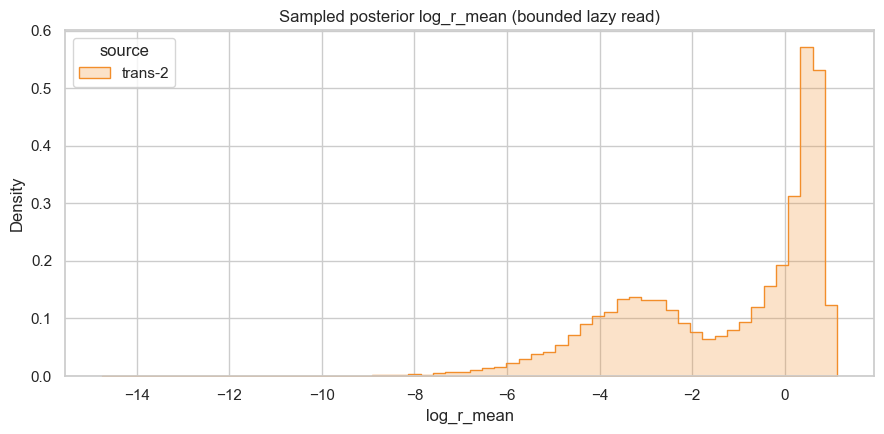

In [10]:
RESULT_GROUPS = ("posterior", "posterior_predictive", "sample_stats", "observed_data")
result_datasets = {}
result_inventory_rows = []
result_error_rows = []
observed_alignment_rows = []
sample_stats_rows = []
posterior_sample_frames = []

for source, path in RESULT_PATHS.items():
    result_datasets[source] = {}
    for group in RESULT_GROUPS:
        try:
            dataset = xr.open_dataset(path, group=group, engine="h5netcdf", chunks={})
            result_datasets[source][group] = dataset
            for variable, array in dataset.data_vars.items():
                result_inventory_rows.append(
                    {
                        "source": source,
                        "group": group,
                        "variable": variable,
                        "dims": tuple(array.dims),
                        "shape": tuple(array.shape),
                        "dtype": str(array.dtype),
                    }
                )
        except Exception as error:
            result_error_rows.append(
                {
                    "source": source,
                    "group": group,
                    "error_type": type(error).__name__,
                    "message": str(error),
                }
            )

    observed = result_datasets[source].get("observed_data")
    if observed is not None:
        starting_equal = np.array_equal(
            observed["starting_counts"].load().values,
            scistanpy_datasets[source]["starting_counts"],
        )
        timepoint_equal = np.array_equal(
            observed["timepoint_counts"].load().values,
            scistanpy_datasets[source]["timepoint_counts"],
        )
        observed_alignment_rows.append(
            {
                "source": source,
                "netcdf_variants": observed.sizes["b"],
                "scistanpy_variants": len(scistanpy_datasets[source]["variants"]),
                "starting_counts_equal": starting_equal,
                "timepoint_counts_equal": timepoint_equal,
            }
        )

    sample_stats = result_datasets[source].get("sample_stats")
    if sample_stats is not None:
        compact_stats = sample_stats.load()
        sample_stats_rows.append(
            {
                "source": source,
                "chains": compact_stats.sizes.get("chain"),
                "draws_per_chain": compact_stats.sizes.get("draw"),
                "divergences": int(compact_stats["divergent__"].sum()),
                "mean_accept_stat": float(compact_stats["accept_stat__"].mean()),
                "max_treedepth": int(compact_stats["treedepth__"].max()),
                "median_stepsize": float(compact_stats["stepsize__"].median()),
            }
        )

    posterior = result_datasets[source].get("posterior")
    if posterior is not None and "log_r_mean" in posterior:
        variable = posterior["log_r_mean"]
        variant_indices = np.linspace(0, variable.sizes["b"] - 1, 300, dtype=int)
        draw_indices = np.linspace(0, variable.sizes["draw"] - 1, 50, dtype=int)
        sampled = variable.isel(chain=slice(0, 2), draw=draw_indices, b=variant_indices).load()
        sampled_frame = sampled.to_dataframe(name="log_r_mean").reset_index()
        sampled_frame["source"] = source
        sampled_frame["aa_seq"] = sampled_frame["b"].astype(int).map(
            dict(enumerate(scistanpy_datasets[source]["variants"]))
        )
        posterior_sample_frames.append(sampled_frame)

result_inventory = pd.DataFrame(result_inventory_rows)
result_errors = pd.DataFrame(result_error_rows)
observed_alignment = pd.DataFrame(observed_alignment_rows)
hmc_diagnostics = pd.DataFrame(sample_stats_rows)
posterior_log_r_sample = (
    pd.concat(posterior_sample_frames, ignore_index=True)
    if posterior_sample_frames
    else pd.DataFrame()
)

display(result_inventory)
if not result_errors.empty:
    print("Unreadable result groups:")
    display(result_errors)
display(observed_alignment)
display(hmc_diagnostics)

if not posterior_log_r_sample.empty:
    fig, ax = plt.subplots(figsize=(9, 4.5))
    sns.histplot(
        data=posterior_log_r_sample,
        x="log_r_mean",
        hue="source",
        palette=SOURCE_COLORS,
        element="step",
        stat="density",
        common_norm=False,
        bins=60,
        ax=ax,
    )
    ax.set_title("Sampled posterior log_r_mean (bounded lazy read)")
    plt.tight_layout()
    plt.show()

## 8. Reconstruct `PDZ:CRIPT` Sequences from SciStanPy Variants

`flip_dsets.py` supplies the canonical grouped variants and count order but does not currently export a trans reconstruction helper. The thin transformation below therefore starts from the SciStanPy-loaded tables:

- trans-1: variable first PDZ half + WT second half;
- trans-2: WT first half + variable second PDZ half;
- CRIPT: final 8 residues of the encoded variant;
- normalize by truncating PDZ and CRIPT independently at the first stop character.

`variant_index` is retained as the exact index along the fit's `b` dimension.

In [11]:
def truncate_at_stop(sequence: str) -> str:
    return sequence.split("*", 1)[0]


def reconstruct_scistanpy_variants(frame: pd.DataFrame, source: str) -> pd.DataFrame:
    reconstructed = frame.copy()
    encoded = reconstructed["aa_seq"].astype(str)

    if source == "trans-1":
        pdz_raw = encoded.str[:PDZ_HALF_LENGTH] + WT_PDZ[PDZ_HALF_LENGTH:]
    elif source == "trans-2":
        pdz_raw = WT_PDZ[:PDZ_HALF_LENGTH] + encoded.str[:PDZ_HALF_LENGTH]
    else:
        raise ValueError(f"Unexpected PDZ trans source: {source}")

    cript_raw = encoded.str[-CRIPT_LENGTH:]
    reconstructed["pdz_sequence_raw"] = pdz_raw
    reconstructed["cript_sequence_raw"] = cript_raw
    reconstructed["raw_sequence"] = pdz_raw + ":" + cript_raw
    reconstructed["pdz_sequence"] = pdz_raw.map(truncate_at_stop)
    reconstructed["cript_sequence"] = cript_raw.map(truncate_at_stop)
    reconstructed["sequence"] = (
        reconstructed["pdz_sequence"] + ":" + reconstructed["cript_sequence"]
    )
    reconstructed["stop_normalized"] = reconstructed["raw_sequence"].ne(
        reconstructed["sequence"]
    )
    return reconstructed


reconstructed_by_source = {
    source: reconstruct_scistanpy_variants(frame, source)
    for source, frame in source_frames.items()
}

reconstruction_profile = pd.DataFrame(
    [
        {
            "source": source,
            "fit_index_rows": len(frame),
            "unique_normalized_sequences": frame["sequence"].nunique(),
            "rows_changed_by_stop_normalization": int(frame["stop_normalized"].sum()),
            "empty_pdz_after_stop": int(frame["pdz_sequence"].eq("").sum()),
            "empty_cript_after_stop": int(frame["cript_sequence"].eq("").sum()),
            "duplicate_normalized_sequence_rows": int(frame["sequence"].duplicated(keep=False).sum()),
        }
        for source, frame in reconstructed_by_source.items()
    ]
)

display(reconstruction_profile)
for source, frame in reconstructed_by_source.items():
    print(f"\n{source} reconstruction mapped from fit index:")
    display(
        frame[
            [
                "source",
                "variant_index",
                "aa_seq",
                "raw_sequence",
                "sequence",
                "stop_normalized",
            ]
        ].head(5)
    )

,source,fit_index_rows,unique_normalized_sequences,rows_changed_by_stop_normalization,empty_pdz_after_stop,empty_cript_after_stop,duplicate_normalized_sequence_rows
0,trans-1,150769,150769,6538,155,959,0
1,trans-2,151624,151624,6585,0,974,0



trans-1 reconstruction mapped from fit index:


,source,variant_index,aa_seq,raw_sequence,sequence,stop_normalized
0,trans-1,0,*EEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGE*NYKQTSV,*EEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:*NYKQTSV,:,True
1,trans-1,1,*EEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGEANYKQTSV,*EEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:ANYKQTSV,:ANYKQTSV,True
2,trans-1,2,*EEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGECNYKQTSV,*EEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:CNYKQTSV,:CNYKQTSV,True
3,trans-1,3,*EEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGEDNYKQTSV,*EEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:DNYKQTSV,:DNYKQTSV,True
4,trans-1,4,*EEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGEENYKQTSV,*EEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:ENYKQTSV,:ENYKQTSV,True



trans-2 reconstruction mapped from fit index:


,source,variant_index,aa_seq,raw_sequence,sequence,stop_normalized
0,trans-2,0,*RKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA*NYKQTSV,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGE*RKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:*NYKQTSV,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGE:,True
1,trans-2,1,*RKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEAANYKQTSV,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGE*RKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:ANYKQTSV,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGE:ANYKQTSV,True
2,trans-2,2,*RKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEACNYKQTSV,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGE*RKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:CNYKQTSV,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGE:CNYKQTSV,True
3,trans-2,3,*RKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEADNYKQTSV,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGE*RKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:DNYKQTSV,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGE:DNYKQTSV,True
4,trans-2,4,*RKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEAENYKQTSV,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGE*RKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:ENYKQTSV,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGE:ENYKQTSV,True


## 9. Verify Reconstruction Against the Manual Method

Re-run the earlier notebook's rules independently on raw rows, then aggregate. This tests that grouping first through SciStanPy and reconstructing second is equivalent to reconstructing raw rows first and grouping afterward.

In [12]:
def manual_reference_reconstruction(frame: pd.DataFrame, source: str) -> pd.DataFrame:
    reference = frame.copy()
    encoded = reference["aa_seq"].astype(str)
    if source == "trans-1":
        pdz = encoded.str.slice(0, 50) + WT_PDZ[50:]
    elif source == "trans-2":
        pdz = WT_PDZ[:50] + encoded.str.slice(0, 50)
    else:
        raise ValueError(source)

    cript = encoded.str.slice(-8)
    reference["sequence"] = (
        pdz.str.split("*", n=1).str[0]
        + ":"
        + cript.str.split("*", n=1).str[0]
    )
    reference["source"] = source
    return reference


parity_rows = []
parity_mismatches = []
manual_aggregated_frames = []
scistanpy_aggregated_frames = []

for source in RAW_PATHS:
    direct_grouped = (
        raw_source_frames[source]
        .groupby("aa_seq", as_index=False)[COUNT_COLUMNS]
        .sum()
    )
    manual_grouped = manual_reference_reconstruction(direct_grouped, source)
    scistanpy_rows = reconstructed_by_source[source]

    key_comparison = scistanpy_rows[["aa_seq", "sequence"]].merge(
        manual_grouped[["aa_seq", "sequence"]],
        on="aa_seq",
        how="outer",
        validate="one_to_one",
        suffixes=("_scistanpy", "_manual"),
        indicator=True,
    )
    key_comparison["sequence_match"] = key_comparison["sequence_scistanpy"].eq(
        key_comparison["sequence_manual"]
    )

    manual_raw = manual_reference_reconstruction(raw_source_frames[source], source)
    manual_aggregated = manual_raw.groupby(["source", "sequence"], as_index=False)[COUNT_COLUMNS].sum()
    scistanpy_aggregated = scistanpy_rows.groupby(["source", "sequence"], as_index=False)[COUNT_COLUMNS].sum()
    aggregate_comparison = scistanpy_aggregated.merge(
        manual_aggregated,
        on=["source", "sequence"],
        how="outer",
        validate="one_to_one",
        suffixes=("_scistanpy", "_manual"),
        indicator=True,
    )
    count_match_columns = []
    for column in COUNT_COLUMNS:
        match_column = f"{column}_match"
        aggregate_comparison[match_column] = aggregate_comparison[f"{column}_scistanpy"].eq(
            aggregate_comparison[f"{column}_manual"]
        )
        count_match_columns.append(match_column)
    aggregate_comparison["all_counts_match"] = aggregate_comparison[count_match_columns].all(axis=1)

    parity_rows.append(
        {
            "source": source,
            "variant_key_rows": len(key_comparison),
            "exact_reconstruction_key_rate": float(key_comparison["sequence_match"].mean()),
            "aggregate_sequence_rows": len(aggregate_comparison),
            "aggregate_count_match_rate": float(aggregate_comparison["all_counts_match"].mean()),
            "stop_related_key_mismatches": int(
                (
                    ~key_comparison["sequence_match"]
                    & key_comparison["aa_seq"].fillna("").str.contains("*", regex=False)
                ).sum()
            ),
        }
    )
    parity_mismatches.append(
        key_comparison.loc[~key_comparison["sequence_match"]].assign(source=source)
    )
    manual_aggregated_frames.append(manual_aggregated)
    scistanpy_aggregated_frames.append(scistanpy_aggregated)

reconstruction_parity = pd.DataFrame(parity_rows)
reconstruction_mismatches = pd.concat(parity_mismatches, ignore_index=True)

assert reconstruction_parity["exact_reconstruction_key_rate"].eq(1.0).all()
assert reconstruction_parity["aggregate_count_match_rate"].eq(1.0).all()

display(reconstruction_parity)
print(f"Representative mismatches: {len(reconstruction_mismatches):,}")
display(reconstruction_mismatches.head(10))

,source,variant_key_rows,exact_reconstruction_key_rate,aggregate_sequence_rows,aggregate_count_match_rate,stop_related_key_mismatches
0,trans-1,150769,1.0,150769,1.0,0
1,trans-2,151624,1.0,151624,1.0,0


Representative mismatches: 0


,aa_seq,sequence_scistanpy,sequence_manual,_merge,sequence_match,source


## 10. Aggregate Counts Across Trans Datasets

Concatenate the SciStanPy-indexed reconstructions and group by normalized `PDZ:CRIPT`. Sum counts, retain source provenance, and count the contributing fit rows and raw variants.

In [13]:
reconstructed_rows = pd.concat(reconstructed_by_source.values(), ignore_index=True)
fit_index_map = reconstructed_rows[
    [
        "source",
        "variant_index",
        "aa_seq",
        "raw_sequence",
        "sequence",
        "pdz_sequence",
        "cript_sequence",
        "stop_normalized",
        *COUNT_COLUMNS,
    ]
].copy()

per_source_counts = {
    source: (
        frame.groupby("sequence", as_index=False)
        .agg(
            {
                **{column: "sum" for column in COUNT_COLUMNS},
                "aa_seq": "nunique",
                "variant_index": "size",
                "stop_normalized": "sum",
            }
        )
        .rename(
            columns={
                "aa_seq": "raw_variant_count",
                "variant_index": "contributing_fit_rows",
                "stop_normalized": "stop_normalized_rows",
            }
        )
        .assign(source=source)
    )
    for source, frame in reconstructed_by_source.items()
}

aggregated_counts = (
    reconstructed_rows.groupby("sequence", as_index=False)
    .agg(
        {
            **{column: "sum" for column in COUNT_COLUMNS},
            "source": lambda values: ",".join(sorted(set(values))),
            "aa_seq": "nunique",
            "variant_index": "size",
            "stop_normalized": "sum",
        }
    )
    .rename(
        columns={
            "aa_seq": "raw_variant_count",
            "variant_index": "contributing_fit_rows",
            "stop_normalized": "stop_normalized_rows",
        }
    )
)
aggregated_counts[["pdz_sequence", "cript_sequence"]] = aggregated_counts[
    "sequence"
].str.split(":", n=1, expand=True)
aggregated_counts["total_input"] = aggregated_counts[INPUT_COLUMNS].sum(axis=1)
aggregated_counts["total_output"] = aggregated_counts[OUTPUT_COLUMNS].sum(axis=1)
aggregated_counts["total_counts"] = (
    aggregated_counts["total_input"] + aggregated_counts["total_output"]
)

aggregation_summary = pd.DataFrame(
    [
        {"metric": "source fit-index rows", "value": len(reconstructed_rows)},
        {"metric": "union normalized sequences", "value": len(aggregated_counts)},
        {
            "metric": "sequences represented by both libraries",
            "value": int(aggregated_counts["source"].eq("trans-1,trans-2").sum()),
        },
        {
            "metric": "rows collapsed across libraries",
            "value": len(reconstructed_rows) - len(aggregated_counts),
        },
    ]
)

display(aggregation_summary)
display(aggregated_counts["source"].value_counts().rename_axis("source").reset_index(name="sequences"))
display(aggregated_counts.head())

,metric,value
0,source fit-index rows,302393
1,union normalized sequences,302237
2,sequences represented by both libraries,156
3,rows collapsed across libraries,156


,source,sequences
0,trans-2,151468
1,trans-1,150613
2,"trans-1,trans-2",156


,sequence,input1_e1_s0_bNA_count,input2_e2_s0_bNA_count,input3_e3_s0_bNA_count,output1A_e1_s1_b1_count,output2A_e2_s1_b1_count,output3A_e3_s1_b1_count,source,raw_variant_count,contributing_fit_rows,stop_normalized_rows,pdz_sequence,cript_sequence,total_input,total_output,total_counts
0,:,5,10,7,0,0,0,trans-1,1,1,1,,,22,0,22
1,:ANYKQTSV,12,22,13,0,0,1,trans-1,1,1,1,,ANYKQTSV,47,1,48
2,:CNYKQTSV,4,5,10,0,1,2,trans-1,1,1,1,,CNYKQTSV,19,3,22
3,:DNYKQTSV,12,14,9,0,0,0,trans-1,1,1,1,,DNYKQTSV,35,0,35
4,:ENYKQTSV,9,24,13,0,0,1,trans-1,1,1,1,,ENYKQTSV,46,1,47


## 11. Load and Normalize the FLIP PDZ Splits

The inspected `flip_dsets.py` snapshot has no public FLIP split loader, so use the local split CSV as an explicit fallback. Apply the same component-wise stop normalization and validate the `PDZ:CRIPT` key structure before merging.

In [14]:
flip_loader_candidates = [
    name
    for name, function in public_functions
    if "flip" in name.lower() and "load" in name.lower()
]
if flip_loader_candidates:
    raise NotImplementedError(
        "A FLIP loader is now available; inspect and adopt it before using the CSV fallback: "
        f"{flip_loader_candidates}"
    )

flip_split = pd.read_csv(FLIP_PATH)
required_flip_columns = {"sequence", "set", "validation", "target"}
missing_flip_columns = sorted(required_flip_columns - set(flip_split.columns))
assert not missing_flip_columns, f"FLIP split is missing columns: {missing_flip_columns}"
assert flip_split["sequence"].notna().all()
assert flip_split["sequence"].str.count(":").eq(1).all(), "FLIP keys must contain one colon."

flip_split = flip_split.rename(columns={"sequence": "sequence_raw"})
flip_components = flip_split["sequence_raw"].str.split(":", n=1, expand=True)
flip_split["pdz_sequence"] = flip_components[0].map(truncate_at_stop)
flip_split["cript_sequence"] = flip_components[1].map(truncate_at_stop)
flip_split["sequence"] = flip_split["pdz_sequence"] + ":" + flip_split["cript_sequence"]
flip_split["normalization_changed"] = flip_split["sequence"].ne(flip_split["sequence_raw"])

flip_summary = pd.DataFrame(
    [
        {"metric": "FLIP rows", "value": len(flip_split)},
        {"metric": "unique raw keys", "value": flip_split["sequence_raw"].nunique()},
        {"metric": "unique normalized keys", "value": flip_split["sequence"].nunique()},
        {"metric": "rows changed by normalization", "value": int(flip_split["normalization_changed"].sum())},
        {"metric": "duplicate normalized-key rows", "value": int(flip_split["sequence"].duplicated(keep=False).sum())},
    ]
)

print("FLIP loading path: local CSV fallback (no public loader in flip_dsets.py)")
display(flip_summary)
display(flip_split.head())

FLIP loading path: local CSV fallback (no public loader in flip_dsets.py)


,metric,value
0,FLIP rows,734
1,unique raw keys,734
2,unique normalized keys,734
3,rows changed by normalization,0
4,duplicate normalized-key rows,0


,sequence_raw,target,set,validation,pdz_sequence,cript_sequence,sequence,normalization_changed
0,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:,-0.834694,train,False,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA,,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:,False
1,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:ANYKQTSV,-0.085543,train,False,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA,ANYKQTSV,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:ANYKQTSV,False
2,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:CNYKQTSV,-0.057949,train,False,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA,CNYKQTSV,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:CNYKQTSV,False
3,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:DNYKQTSV,-0.164924,train,False,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA,DNYKQTSV,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:DNYKQTSV,False
4,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:ENYKQTSV,-0.150309,train,False,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA,ENYKQTSV,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:ENYKQTSV,False


## 12. Reconcile Reconstructed Sequences with FLIP

Compare FLIP coverage from trans-1, trans-2, and their union. The union merge attaches grouped counts and source provenance to each FLIP row with a strict one-to-one key validation.

In [15]:
reconstruction_sets = {
    "trans-1": set(per_source_counts["trans-1"]["sequence"]),
    "trans-2": set(per_source_counts["trans-2"]["sequence"]),
    "union": set(aggregated_counts["sequence"]),
}

coverage_frames = []
overall_coverage_rows = []
for reconstruction_source, sequence_set in reconstruction_sets.items():
    source_coverage = flip_split[["sequence", "set", "validation"]].copy()
    source_coverage["reconstruction_source"] = reconstruction_source
    source_coverage["matched"] = source_coverage["sequence"].isin(sequence_set)
    coverage_frames.append(
        source_coverage.groupby(
            ["reconstruction_source", "set", "validation"],
            dropna=False,
            as_index=False,
        ).agg(
            flip_rows=("sequence", "size"),
            matched_rows=("matched", "sum"),
            coverage=("matched", "mean"),
        )
    )
    overall_coverage_rows.append(
        {
            "reconstruction_source": reconstruction_source,
            "flip_rows": len(source_coverage),
            "matched_rows": int(source_coverage["matched"].sum()),
            "coverage": float(source_coverage["matched"].mean()),
        }
    )

coverage_by_split = pd.concat(coverage_frames, ignore_index=True)
overall_coverage = pd.DataFrame(overall_coverage_rows)

flip_with_counts = flip_split.merge(
    aggregated_counts,
    on="sequence",
    how="left",
    validate="one_to_one",
    indicator=True,
    suffixes=("_flip", "_counts"),
)
flip_with_counts["matched"] = flip_with_counts["_merge"].eq("both")
matched_flip_counts = flip_with_counts.loc[flip_with_counts["matched"]].copy()
flip_only_sequences = flip_with_counts.loc[~flip_with_counts["matched"]].copy()
reconstructed_only_sequences = aggregated_counts.loc[
    ~aggregated_counts["sequence"].isin(flip_split["sequence"])
].copy()

merge_summary = pd.DataFrame(
    [
        {"metric": "FLIP rows", "value": len(flip_with_counts)},
        {"metric": "matched FLIP rows", "value": len(matched_flip_counts)},
        {"metric": "FLIP-only rows", "value": len(flip_only_sequences)},
        {"metric": "reconstructed-only rows", "value": len(reconstructed_only_sequences)},
        {"metric": "union FLIP coverage", "value": float(flip_with_counts["matched"].mean())},
    ]
)

display(overall_coverage)
display(coverage_by_split)
display(merge_summary)
print("FLIP-only examples:")
display(flip_only_sequences[["sequence", "set", "validation", "target"]].head(10))
print("Reconstructed-only examples:")
display(
    reconstructed_only_sequences[
        ["sequence", "source", "total_input", "total_output", "raw_variant_count"]
    ].head(10)
)

,reconstruction_source,flip_rows,matched_rows,coverage
0,trans-1,734,581,0.791553
1,trans-2,734,308,0.419619
2,union,734,734,1.000000


,reconstruction_source,set,validation,flip_rows,matched_rows,coverage
0,trans-1,test,False,579,426,0.735751
1,trans-1,train,False,124,124,1.000000
2,trans-1,train,True,31,31,1.000000
3,trans-2,test,False,579,153,0.264249
4,trans-2,train,False,124,124,1.000000
5,trans-2,train,True,31,31,1.000000
6,union,test,False,579,579,1.000000
7,union,train,False,124,124,1.000000
8,union,train,True,31,31,1.000000


,metric,value
0,FLIP rows,734.0
1,matched FLIP rows,734.0
2,FLIP-only rows,0.0
3,reconstructed-only rows,301503.0
4,union FLIP coverage,1.0


FLIP-only examples:


,sequence,set,validation,target


Reconstructed-only examples:


,sequence,source,total_input,total_output,raw_variant_count
0,:,trans-1,22,0,1
1,:ANYKQTSV,trans-1,47,1,1
2,:CNYKQTSV,trans-1,19,3,1
3,:DNYKQTSV,trans-1,35,0,1
4,:ENYKQTSV,trans-1,46,1,1
5,:FNYKQTSV,trans-1,20,1,1
6,:GNYKQTSV,trans-1,28,2,1
7,:HNYKQTSV,trans-1,24,1,1
8,:INYKQTSV,trans-1,37,2,1
9,:K,trans-1,38,0,1


## 13. Visualize FLIP Coverage and Dataset Composition

Visualize coverage by split, the source provenance of matched FLIP keys, count depth for matched versus reconstructed-only sequences, and the exact set-membership overlap among trans-1, trans-2, and FLIP.

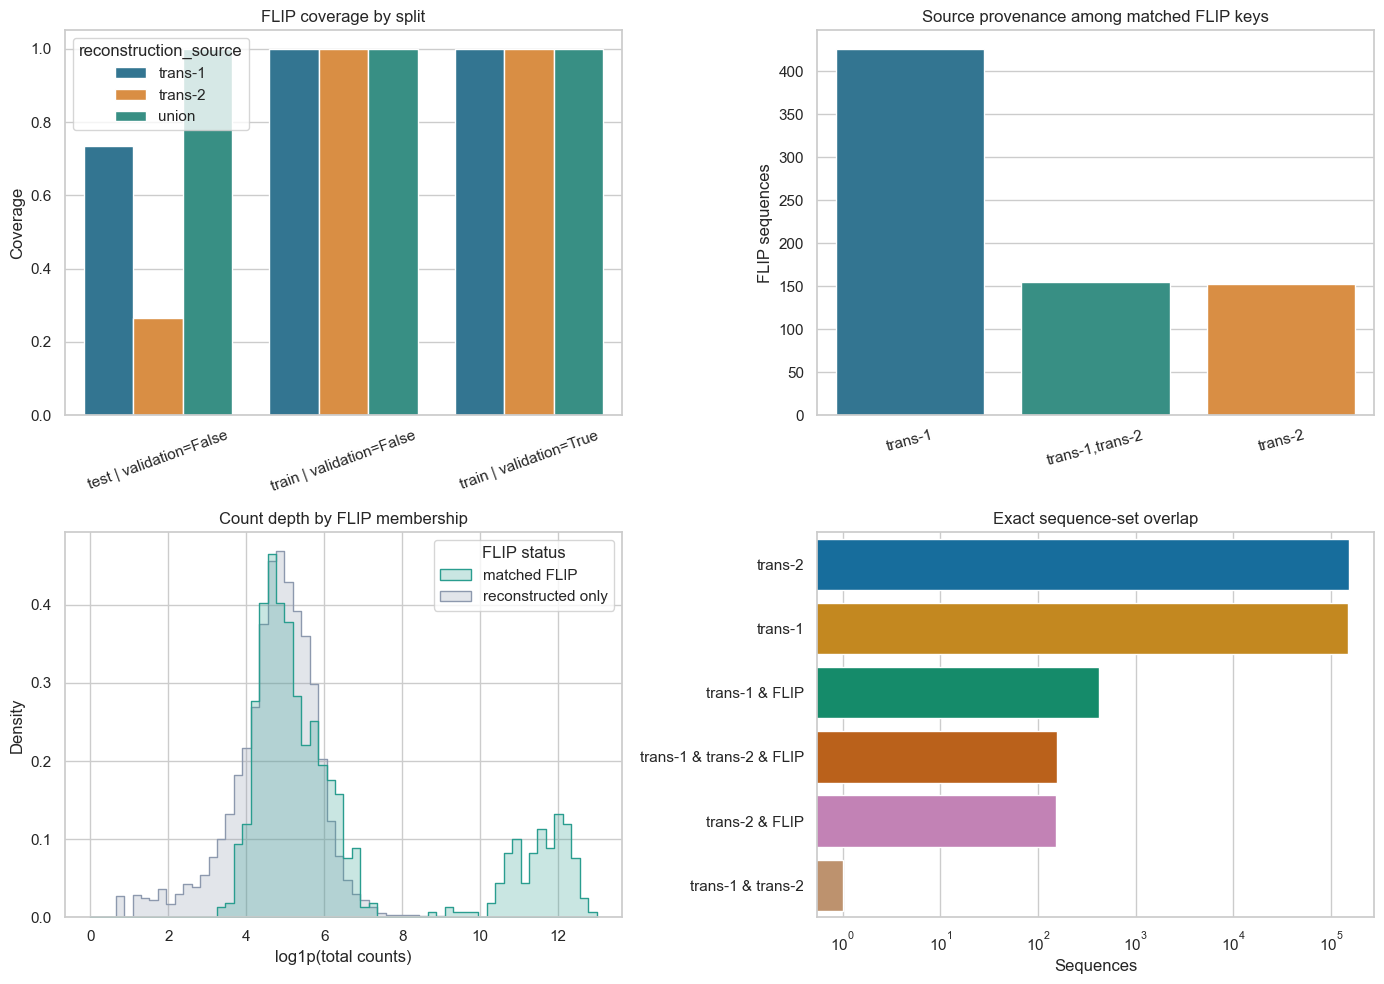

,membership,sequences
0,trans-2,151315
1,trans-1,150187
2,trans-1 & FLIP,426
3,trans-1 & trans-2 & FLIP,155
4,trans-2 & FLIP,153
5,trans-1 & trans-2,1


In [16]:
coverage_plot = coverage_by_split.copy()
coverage_plot["split"] = (
    coverage_plot["set"].astype(str)
    + " | validation="
    + coverage_plot["validation"].astype(str)
)

matched_source_counts = (
    matched_flip_counts["source"].value_counts().rename_axis("source").reset_index(name="FLIP sequences")
)

composition_depth = aggregated_counts[["sequence", "total_counts"]].copy()
composition_depth["FLIP status"] = np.where(
    composition_depth["sequence"].isin(flip_split["sequence"]),
    "matched FLIP",
    "reconstructed only",
)
composition_depth["log1p_total_counts"] = np.log1p(composition_depth["total_counts"])

all_sequences = set().union(*reconstruction_sets.values(), set(flip_split["sequence"]))
overlap_rows = []
for sequence in all_sequences:
    memberships = [
        label
        for label, sequence_set in [
            ("trans-1", reconstruction_sets["trans-1"]),
            ("trans-2", reconstruction_sets["trans-2"]),
            ("FLIP", set(flip_split["sequence"])),
        ]
        if sequence in sequence_set
    ]
    overlap_rows.append(" & ".join(memberships))
overlap_counts = (
    pd.Series(overlap_rows, name="membership")
    .value_counts()
    .rename_axis("membership")
    .reset_index(name="sequences")
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.barplot(
    data=coverage_plot,
    x="split",
    y="coverage",
    hue="reconstruction_source",
    palette={"trans-1": "#247BA0", "trans-2": "#F28E2B", "union": "#2A9D8F"},
    ax=axes[0, 0],
)
axes[0, 0].set(title="FLIP coverage by split", xlabel="", ylabel="Coverage", ylim=(0, 1.05))
axes[0, 0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=matched_source_counts,
    x="source",
    y="FLIP sequences",
    hue="source",
    palette={"trans-1": "#247BA0", "trans-2": "#F28E2B", "trans-1,trans-2": "#2A9D8F"},
    legend=False,
    ax=axes[0, 1],
)
axes[0, 1].set(title="Source provenance among matched FLIP keys", xlabel="")
axes[0, 1].tick_params(axis="x", rotation=15)

plot_depth = pd.concat(
    [
        group.sample(min(30_000, len(group)), random_state=13)
        for _, group in composition_depth.groupby("FLIP status")
    ],
    ignore_index=True,
)
sns.histplot(
    data=plot_depth,
    x="log1p_total_counts",
    hue="FLIP status",
    element="step",
    stat="density",
    common_norm=False,
    bins=60,
    palette={"matched FLIP": "#2A9D8F", "reconstructed only": "#8D99AE"},
    ax=axes[1, 0],
)
axes[1, 0].set(title="Count depth by FLIP membership", xlabel="log1p(total counts)")

sns.barplot(
    data=overlap_counts,
    x="sequences",
    y="membership",
    hue="membership",
    palette="colorblind",
    legend=False,
    ax=axes[1, 1],
)
axes[1, 1].set(title="Exact sequence-set overlap", xlabel="Sequences", ylabel="")
axes[1, 1].set_xscale("log")

plt.tight_layout()
plt.show()
display(overlap_counts)

### Extract HMC Rows for FLIP Sequences Only

Use the SciStanPy-derived `variant_index` as the positional selector for the HMC `b` dimension. `hmc_flip_posterior[source]` retains every posterior variable, chain, and draw for only the variants whose normalized `PDZ:CRIPT` key occurs in FLIP; these xarray datasets remain lazy.

For an immediately inspectable table, `flip_hmc_log_r_summary` summarizes `log_r_mean` using a bounded, evenly spaced draw sample. Increase `HMC_SUMMARY_DRAWS` or calculate directly from the lazy selected datasets when an exact full-draw summary is needed.

In [17]:
HMC_SUMMARY_DRAWS = 100

flip_metadata = flip_split[
    ["sequence", "sequence_raw", "pdz_sequence", "cript_sequence", "target", "set", "validation"]
].copy()
flip_fit_index_map = (
    fit_index_map.merge(
        flip_metadata,
        on="sequence",
        how="inner",
        validate="many_to_one",
        suffixes=("_reconstructed", "_flip"),
    )
    .sort_values(["source", "variant_index"])
    .reset_index(drop=True)
)

hmc_flip_posterior = {}
hmc_flip_extraction_rows = []
log_r_summary_frames = []

for source in RAW_PATHS:
    source_map = (
        flip_fit_index_map.loc[flip_fit_index_map["source"].eq(source)]
        .sort_values("variant_index")
        .reset_index(drop=True)
    )
    posterior = result_datasets.get(source, {}).get("posterior")

    if posterior is None:
        source_errors = result_errors.loc[
            result_errors["source"].eq(source), ["error_type", "message"]
        ]
        hmc_flip_extraction_rows.append(
            {
                "source": source,
                "matched_fit_rows": len(source_map),
                "posterior_available": False,
                "selected_b_rows": 0,
                "status": (
                    source_errors.iloc[0]["message"]
                    if not source_errors.empty
                    else "posterior group unavailable"
                ),
            }
        )
        continue

    assert source_map["variant_index"].is_unique
    variant_indices = source_map["variant_index"].to_numpy(dtype=int)
    indexer = xr.DataArray(variant_indices, dims="flip_variant")
    selected = posterior.isel(b=indexer).assign_coords(
        source=source,
        variant_index=("flip_variant", variant_indices),
        sequence=("flip_variant", source_map["sequence"].to_numpy()),
        pdz_sequence=("flip_variant", source_map["pdz_sequence_flip"].to_numpy()),
        cript_sequence=("flip_variant", source_map["cript_sequence_flip"].to_numpy()),
        target=("flip_variant", source_map["target"].to_numpy()),
        split=("flip_variant", source_map["set"].to_numpy()),
        validation=("flip_variant", source_map["validation"].to_numpy()),
    )
    hmc_flip_posterior[source] = selected

    hmc_flip_extraction_rows.append(
        {
            "source": source,
            "matched_fit_rows": len(source_map),
            "posterior_available": True,
            "selected_b_rows": selected.sizes["flip_variant"],
            "status": "lazy posterior subset ready",
        }
    )

    if "log_r_mean" in selected:
        n_draws = selected.sizes["draw"]
        draw_indices = np.linspace(
            0,
            n_draws - 1,
            min(HMC_SUMMARY_DRAWS, n_draws),
            dtype=int,
        )
        sampled_log_r = selected["log_r_mean"].isel(draw=draw_indices).load()
        reduction_dims = [dim for dim in ("chain", "draw") if dim in sampled_log_r.dims]
        quantiles = sampled_log_r.quantile([0.025, 0.5, 0.975], dim=reduction_dims)

        source_summary = source_map[
            ["source", "variant_index", "sequence", "target", "set", "validation"]
        ].copy()
        source_summary["hmc_draws_sampled_per_chain"] = len(draw_indices)
        source_summary["log_r_mean_posterior_mean"] = sampled_log_r.mean(dim=reduction_dims).values
        source_summary["log_r_mean_posterior_sd"] = sampled_log_r.std(dim=reduction_dims).values
        source_summary["log_r_mean_q025"] = quantiles.sel(quantile=0.025).values
        source_summary["log_r_mean_median"] = quantiles.sel(quantile=0.5).values
        source_summary["log_r_mean_q975"] = quantiles.sel(quantile=0.975).values
        log_r_summary_frames.append(source_summary)

hmc_flip_extraction_status = pd.DataFrame(hmc_flip_extraction_rows)
flip_hmc_log_r_summary = (
    pd.concat(log_r_summary_frames, ignore_index=True)
    if log_r_summary_frames
    else pd.DataFrame()
)

assert len(flip_fit_index_map) == sum(
    len(frame.loc[frame["sequence"].isin(flip_split["sequence"])])
    for frame in reconstructed_by_source.values()
)
for source, selected in hmc_flip_posterior.items():
    expected_rows = int(
        flip_fit_index_map["source"].eq(source).sum()
    )
    assert selected.sizes["flip_variant"] == expected_rows

print("Lazy HMC subsets are available in hmc_flip_posterior.")
display(hmc_flip_extraction_status)
display(flip_fit_index_map.head())
display(flip_hmc_log_r_summary.head())

Lazy HMC subsets are available in hmc_flip_posterior.


,source,matched_fit_rows,posterior_available,selected_b_rows,status
0,trans-1,581,False,0,'Unable to synchronously open object (len not positive after adjustment for EOA)'
1,trans-2,308,True,308,lazy posterior subset ready


,source,variant_index,aa_seq,raw_sequence,sequence,pdz_sequence_reconstructed,cript_sequence_reconstructed,stop_normalized,input1_e1_s0_bNA_count,input2_e2_s0_bNA_count,input3_e3_s0_bNA_count,output1A_e1_s1_b1_count,output2A_e2_s1_b1_count,output3A_e3_s1_b1_count,sequence_raw,pdz_sequence_flip,cript_sequence_flip,target,set,validation
0,trans-1,377,CEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGEKNYKQHSV,CEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNYKQHSV,CEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNYKQHSV,CEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA,KNYKQHSV,False,38,49,28,4,58,5,CEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNYKQHSV,CEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA,KNYKQHSV,-0.478993,test,False
1,trans-1,1359,GCEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGEKNYKQVSV,GCEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNYKQVSV,GCEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNYKQVSV,GCEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA,KNYKQVSV,False,47,57,48,5,62,5,GCEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNYKQVSV,GCEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA,KNYKQVSV,-0.514674,test,False
2,trans-1,1779,GEADIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGEKNYKQKSV,GEADIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNYKQKSV,GEADIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNYKQKSV,GEADIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA,KNYKQKSV,False,7,15,18,1,28,1,GEADIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNYKQKSV,GEADIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA,KNYKQKSV,-0.408205,test,False
3,trans-1,1805,GEADIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGEKNYKQTSE,GEADIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNYKQTSE,GEADIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNYKQTSE,GEADIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA,KNYKQTSE,False,19,22,18,2,6,6,GEADIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNYKQTSE,GEADIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA,KNYKQTSE,-0.535985,test,False
4,trans-1,2094,GEDDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGEKNYKQNSV,GEDDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNYKQNSV,GEDDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNYKQNSV,GEDDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA,KNYKQNSV,False,54,10,18,74,3,0,GEDDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNYKQNSV,GEDDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA,KNYKQNSV,-0.318259,test,False


,source,variant_index,sequence,target,set,validation,hmc_draws_sampled_per_chain,log_r_mean_posterior_mean,log_r_mean_posterior_sd,log_r_mean_q025,log_r_mean_median,log_r_mean_q975
0,trans-2,1006,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGEGRKGDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNYKQNSV,-0.512955,test,False,100,-3.538859,1.348709,-6.503344,-3.311861,-1.619062
1,trans-2,5782,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKDDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNGKQTSV,-0.301669,test,False,100,-0.388878,0.202345,-0.855158,-0.369192,-0.058709
2,trans-2,5789,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKDDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNPKQTSV,-0.210411,test,False,100,0.007984,0.152374,-0.303970,0.022774,0.287399
3,trans-2,5791,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKDDQILSVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNRKQTSV,-0.148026,test,False,100,0.298287,0.104466,0.079224,0.304850,0.486282
4,trans-2,12359,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFISFILAGGPADLSGELRKGDQILEVNGVDLRNASHEQAAIALKNAGQTVTIIAQYKPEEYSRFEA:KNYKQCSV,-0.406984,test,False,100,-3.007806,1.230726,-6.083362,-2.780206,-1.209481


## 14. Run Integrity Assertions

Collect the pipeline invariants in one executable cell: count conservation, unique grouped keys and fit indices, valid key formatting, exact reconstruction parity, one-to-one FLIP merging, coverage consistency, and count alignment for every readable HMC artifact.

In [18]:
raw_count_totals = sum(
    (frame[COUNT_COLUMNS].sum() for frame in raw_source_frames.values()),
    start=pd.Series(0, index=COUNT_COLUMNS, dtype="int64"),
)
aggregated_count_totals = aggregated_counts[COUNT_COLUMNS].sum()
count_conservation = raw_count_totals.eq(aggregated_count_totals)

union_coverage_reported = float(
    overall_coverage.loc[
        overall_coverage["reconstruction_source"].eq("union"), "coverage"
    ].iloc[0]
)
union_coverage_from_merge = float(flip_with_counts["matched"].mean())

integrity_checks = pd.DataFrame(
    [
        {"check": "all count columns conserved", "passed": bool(count_conservation.all())},
        {"check": "aggregated sequence keys unique", "passed": bool(aggregated_counts["sequence"].is_unique)},
        {"check": "fit index unique within source", "passed": bool(~fit_index_map.duplicated(["source", "variant_index"]).any())},
        {"check": "one colon in reconstructed keys", "passed": bool(aggregated_counts["sequence"].str.count(":").eq(1).all())},
        {"check": "one colon in FLIP keys", "passed": bool(flip_split["sequence"].str.count(":").eq(1).all())},
        {"check": "manual reconstruction parity", "passed": bool(reconstruction_parity["exact_reconstruction_key_rate"].eq(1.0).all())},
        {"check": "manual count parity", "passed": bool(reconstruction_parity["aggregate_count_match_rate"].eq(1.0).all())},
        {"check": "FLIP merge preserved row count", "passed": len(flip_with_counts) == len(flip_split)},
        {"check": "FLIP and grouped keys one-to-one", "passed": bool(flip_split["sequence"].is_unique and aggregated_counts["sequence"].is_unique)},
        {"check": "coverage agrees with merge indicator", "passed": bool(np.isclose(union_coverage_reported, union_coverage_from_merge))},
        {"check": "readable HMC observed counts aligned", "passed": bool(observed_alignment.empty or observed_alignment[["starting_counts_equal", "timepoint_counts_equal"]].all().all())},
        {"check": "HMC FLIP selectors unique", "passed": bool(~flip_fit_index_map.duplicated(["source", "variant_index"]).any())},
    ]
)

assert integrity_checks["passed"].all(), integrity_checks.loc[~integrity_checks["passed"]]
display(integrity_checks)
display(
    pd.DataFrame(
        {
            "count_column": COUNT_COLUMNS,
            "raw_total": raw_count_totals.values,
            "aggregated_total": aggregated_count_totals.values,
            "conserved": count_conservation.values,
        }
    )
)

,check,passed
0,all count columns conserved,True
1,aggregated sequence keys unique,True
2,fit index unique within source,True
3,one colon in reconstructed keys,True
4,one colon in FLIP keys,True
5,manual reconstruction parity,True
6,manual count parity,True
7,FLIP merge preserved row count,True
8,FLIP and grouped keys one-to-one,True
9,coverage agrees with merge indicator,True


,count_column,raw_total,aggregated_total,conserved
0,input1_e1_s0_bNA_count,8985517,8985517,True
1,input2_e2_s0_bNA_count,9562059,9562059,True
2,input3_e3_s0_bNA_count,11431152,11431152,True
3,output1A_e1_s1_b1_count,14543902,14543902,True
4,output2A_e2_s1_b1_count,23098815,23098815,True
5,output3A_e3_s1_b1_count,10990433,10990433,True


## 15. Export Reproducible Analysis Tables

Exports are disabled by default. The optional HMC NetCDF export writes the lazy posterior subsets containing only FLIP-matched variants, but can still be large because it retains every posterior variable, chain, and draw.

In [19]:
write_outputs = False
write_hmc_subsets = False

csv_outputs = {
    "pdz_trans_fit_index_map.csv": fit_index_map,
    "pdz_trans_aggregated_counts.csv": aggregated_counts,
    "pdz_trans_reconstruction_parity.csv": reconstruction_parity,
    "pdz_trans_flip_matched_counts.csv": matched_flip_counts,
    "pdz_trans_flip_only_sequences.csv": flip_only_sequences,
    "pdz_trans_reconstructed_only_sequences.csv": reconstructed_only_sequences,
    "pdz_trans_flip_coverage_overall.csv": overall_coverage,
    "pdz_trans_flip_coverage_by_split.csv": coverage_by_split,
    "pdz_trans_hmc_extraction_status.csv": hmc_flip_extraction_status,
    "pdz_trans_flip_hmc_log_r_summary.csv": flip_hmc_log_r_summary,
}
for source, frame in reconstructed_by_source.items():
    csv_outputs[f"pdz_{source}_reconstructed_fit_rows.csv"] = frame

if write_outputs:
    output_dir.mkdir(parents=True, exist_ok=True)
    for filename, frame in csv_outputs.items():
        frame.to_csv(output_dir / filename, index=False)
    print(f"Wrote {len(csv_outputs)} CSV files to {output_dir}")
else:
    print("write_outputs is False; no CSV files written.")
    display(
        pd.DataFrame(
            {
                "available_output": list(csv_outputs),
                "rows_if_written": [len(frame) for frame in csv_outputs.values()],
            }
        )
    )

if write_hmc_subsets:
    output_dir.mkdir(parents=True, exist_ok=True)
    for source, selected in hmc_flip_posterior.items():
        path = output_dir / f"pdz_{source}_flip_only_hmc_posterior.nc"
        selected.to_netcdf(path, engine="h5netcdf")
        print(f"Wrote lazy HMC subset to {path}")
else:
    print("write_hmc_subsets is False; no posterior NetCDF files written.")

write_outputs is False; no CSV files written.


,available_output,rows_if_written
0,pdz_trans_fit_index_map.csv,302393
1,pdz_trans_aggregated_counts.csv,302237
2,pdz_trans_reconstruction_parity.csv,2
3,pdz_trans_flip_matched_counts.csv,734
4,pdz_trans_flip_only_sequences.csv,0
5,pdz_trans_reconstructed_only_sequences.csv,301503
6,pdz_trans_flip_coverage_overall.csv,3
7,pdz_trans_flip_coverage_by_split.csv,9
8,pdz_trans_hmc_extraction_status.csv,2
9,pdz_trans_flip_hmc_log_r_summary.csv,308


write_hmc_subsets is False; no posterior NetCDF files written.
